In [35]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from math import pi
import time

from sklearn.metrics import roc_auc_score, accuracy_score
from sklearn.preprocessing import MinMaxScaler
from qiskit import QuantumCircuit
from qiskit import QuantumRegister, ClassicalRegister
from qiskit.quantum_info import Statevector
from qiskit.circuit.library import efficient_su2, real_amplitudes, pauli_two_design
from qiskit_machine_learning.neural_networks import SamplerQNN, EstimatorQNN
# from qiskit.primitives import StatevectorSampler as Sampler
from qiskit_machine_learning.optimizers import COBYLA
from qiskit_machine_learning.utils import algorithm_globals
from IPython.display import clear_output

import tensorflow as tf
from keras import layers

algorithm_globals.random_seed = 42

In [36]:
from qiskit.circuit import QuantumCircuit, ParameterVector
from qiskit.circuit.library import EfficientSU2, RealAmplitudes
import numpy as np

def angle_encoding(x):
    num_qubits = len(x)
    circuit = QuantumCircuit(num_qubits)
    for i in range(num_qubits):
        circuit.ry(x[i], i)
    return circuit

def dense_angle_encoding(x):
    num_qubits = len(x) // 2
    circuit = QuantumCircuit(num_qubits)
    for i in range(num_qubits):
        circuit.ry(x[2 * i], i)
        circuit.rz(x[2 * i + 1], i)
    return circuit

def efficient_su2_encoding(x):
    num_qubits = int(np.ceil(len(x) / 4))  # EfficientSU2 expects 4 params per qubit per rep
    su2 = EfficientSU2(num_qubits=num_qubits, reps=3)

    # Pad x to match the number of parameters in EfficientSU2
    total_params = su2.num_parameters
    padded_x = np.pad(x, (0, total_params - len(x)), mode='constant')

    circuit = QuantumCircuit(num_qubits)
    circuit.compose(su2.assign_parameters(padded_x), inplace=True)
    return circuit

def amplitude_encoding(x):

    x = np.asarray(x, dtype=np.float64)

    # Replace NaNs and Infs with 0 BEFORE padding
    if not np.all(np.isfinite(x)):
        x = np.nan_to_num(x, nan=0.0, posinf=0.0, neginf=0.0)

    # Pad first
    num_qubits = int(np.ceil(np.log2(len(x))))
    target_len = 2 ** num_qubits
    padded = np.pad(x, (0, target_len - len(x))).astype(np.float64)

    # Normalize
    norm = np.linalg.norm(padded)
    if norm == 0 or not np.isfinite(norm):
        # Default to |0⟩ state if invalid
        normalized = np.zeros_like(padded)
        normalized[0] = 1.0
    else:
        normalized = padded / norm

    # Safety check (this ensures Qiskit won't throw)
    assert np.isclose(np.sum(normalized**2), 1.0, atol=1e-10), f"Vector not normalized: {np.sum(normalized**2)}"

    # Create circuit
    circuit = QuantumCircuit(num_qubits)
    circuit.initialize(normalized, range(num_qubits))
    return circuit


def build_encoded_circuits(data, encoding_fn):
    circuits = []
    for x in data:
        circuit = encoding_fn(x)
        circuits.append(circuit)
    return circuits

def ansatz(num_qubits):
    # return real_amplitudes(num_qubits, reps=1)
    return pauli_two_design(num_qubits, reps=1)

def auto_encoder_circuit(num_latent, num_trash):
    qr = QuantumRegister(num_latent + 2 * num_trash + 1, "q")
    cr = ClassicalRegister(1, "c")
    circuit = QuantumCircuit(qr, cr)
    circuit.compose(ansatz(num_latent + num_trash), range(0, num_latent + num_trash), inplace=True)
    circuit.barrier()
    auxiliary_qubit = num_latent + 2 * num_trash
    # swap test
    circuit.h(auxiliary_qubit)
    for i in range(num_trash):
        circuit.cswap(auxiliary_qubit, num_latent + i, num_latent + num_trash + i)

    circuit.h(auxiliary_qubit)
    circuit.measure(auxiliary_qubit, cr[0])
    return circuit

In [37]:
from numpy import sqrt
from qiskit.qpy import load

# Constants
num_latent = 2
num_trash = 2
total_qubits = num_latent + 2 * num_trash + 1  # encoding + reference + auxiliary

# Create Circuit
# ae = auto_encoder_circuit(num_latent, num_trash)

# Generate some random values to bind to the AE parameters
# param_values = np.random.uniform(0, 2 * np.pi, len(ae.parameters))
# ae = ae.assign_parameters({p: v for p, v in zip(ae.parameters, param_values)})

model_name = "Models/QAE/First_N/8f_qae_dense_ra2_5k"
trained_params = np.load(f"{model_name}/trained_parameters.npy")
with open(f"{model_name}/ae.qpy", "rb") as f:
    ae = load(f)[0]  # returns a list of circuits

# ae = ae.assign_parameters({p: v for p, v in zip(ae.parameters, trained_params)})

# # State Prep
# vec = [sqrt(0.5), 0, 0, sqrt(0.5)]  # For 2 qubits (like |00⟩ + |11⟩)
# Statevector(vec).draw('latex')  # Visualize

# # QC Init
# encoding = QuantumCircuit(total_qubits)
# encoding.initialize(vec, [0, 1])  # Targeting qubit 0 and 1

# qc_full = encoding.compose(ae)
# qc_full.draw('mpl') 


In [38]:
transformed_training_data = pd.read_csv('Dataset/Transformed/Normalised/labelled_transformed_training_data.csv')

# 1. Extract labels (column 6)
training_labels = transformed_training_data.iloc[:, 6].astype(bool)  # Anomalies: True

# 2. Drop label and extra column (column 6 and 7)
training_data = transformed_training_data.drop(
    columns=[transformed_training_data.columns[6], transformed_training_data.columns[7]]
)

# 3. Convert to float32 tensor
training_data = tf.convert_to_tensor(training_data.values, dtype=tf.float32)

# 4. Convert labels to tensor (bool)
training_labels = tf.convert_to_tensor(training_labels.values, dtype=tf.bool)

# 5. Split normal vs anomalous
normal_training_data = tf.boolean_mask(training_data, ~training_labels)
anomalous_training_data = tf.boolean_mask(training_data, training_labels)

transformed_testing_data = pd.read_csv('Dataset/Transformed/Normalised/labelled_transformed_testing_data.csv')

# 1. Extract labels (column 6)
testing_labels = transformed_testing_data.iloc[:, 6].astype(bool)  # Anomalies: True

# 2. Drop label and extra column (column 6 and 7)
testing_data = transformed_testing_data.drop(
    columns=[transformed_testing_data.columns[6], transformed_testing_data.columns[7]]
)

# 3. Convert to float32 tensor
testing_data = tf.convert_to_tensor(testing_data.values, dtype=tf.float32)

# 4. Convert labels to tensor (bool)
testing_labels = tf.convert_to_tensor(testing_labels.values, dtype=tf.bool)

# 5. Split normal vs anomalous
normal_testing_data = tf.boolean_mask(testing_data, ~testing_labels)
anomalous_testing_data = tf.boolean_mask(testing_data, testing_labels)

transformed_validation_data = pd.read_csv('Dataset/Transformed/Normalised/labelled_transformed_validation_data.csv')

# 1. Extract labels (column 6)
validation_labels = transformed_validation_data.iloc[:, 6].astype(bool)  # Anomalies: True

# 2. Drop label and extra column (column 6 and 7)
validation_data = transformed_validation_data.drop(
    columns=[transformed_validation_data.columns[6], transformed_validation_data.columns[7]]
)

# 3. Convert to float32 tensor
validation_data = tf.convert_to_tensor(validation_data.values, dtype=tf.float32)

# 4. Convert labels to tensor (bool)
validation_labels = tf.convert_to_tensor(validation_labels.values, dtype=tf.bool)

# 5. Split normal vs anomalous
normal_validation_data = tf.boolean_mask(validation_data, ~validation_labels)
anomalous_validation_data = tf.boolean_mask(validation_data, validation_labels)

In [39]:
import time
from sklearn.preprocessing import MinMaxScaler

start_time = time.time()

reduced_testing_data = testing_data
scaler = MinMaxScaler(feature_range=(0, np.pi))
scaled_testing_data = scaler.fit_transform(reduced_testing_data)
# scaled_testing_data = reduced_testing_data

reduced_normal_training_data = normal_training_data
scaler = MinMaxScaler(feature_range=(0, np.pi))
scaled_normal_training_data = scaler.fit_transform(reduced_normal_training_data)
# scaled_normal_training_data = reduced_normal_training_data

reduced_validation_data = validation_data
scaler = MinMaxScaler(feature_range=(0, np.pi))
scaled_validation_data = scaler.fit_transform(reduced_validation_data)
# scaled_validation_data = reduced_validation_data

first_n_scaled_normal_training_data = scaled_normal_training_data[:, :8]
first_n_scaled_validation_data = scaled_validation_data[:, :8]
first_n_scaled_testing_data = scaled_testing_data[:, :8]

In [40]:
from scipy.stats import entropy
# === Expressibility calculation ===
def compute_expressibility_dataset(encoding_fn, data, num_samples=200):
    """Computes expressibility following Sim et al. (2019) as KL divergence
       between encoded state distribution and Haar random states."""
    # Get encoded statevectors
    encoded_states = []
    for i in np.random.choice(len(data), size=num_samples, replace=False):
        qc = encoding_fn(data[i])
        sv = Statevector.from_instruction(qc)
        encoded_states.append(sv.data)

    # Compute distribution of fidelities between random pairs
    fidelities = []
    for i in range(len(encoded_states)):
        for j in range(i+1, len(encoded_states)):
            f = np.abs(np.vdot(encoded_states[i], encoded_states[j]))**2
            fidelities.append(f)

    # Compare to Haar-random fidelity distribution
    haar_samples = np.random.rand(len(fidelities))  # Uniform[0,1] approx Haar
    hist_encoded, _ = np.histogram(fidelities, bins=50, range=(0,1), density=True)
    hist_haar, _ = np.histogram(haar_samples, bins=50, range=(0,1), density=True)

    hist_encoded += 1e-12  # avoid log(0)
    hist_haar += 1e-12
    return -entropy(hist_encoded, hist_haar)  # KL divergence negative → higher expressibility

Computing expressibility:  25%|███▎         | 1/4 [00:00<00:00,  3.96encoding/s]

Amplitude expressibility ≈ -2.006


Computing expressibility:  50%|██████▌      | 2/4 [00:00<00:00,  3.77encoding/s]

Angle expressibility ≈ -3.024


Computing expressibility:  75%|█████████▊   | 3/4 [00:00<00:00,  4.11encoding/s]

Dense-Angle expressibility ≈ -2.856


Computing expressibility: 100%|█████████████| 4/4 [00:02<00:00,  1.93encoding/s]

EfficientSU2 expressibility ≈ -2.656


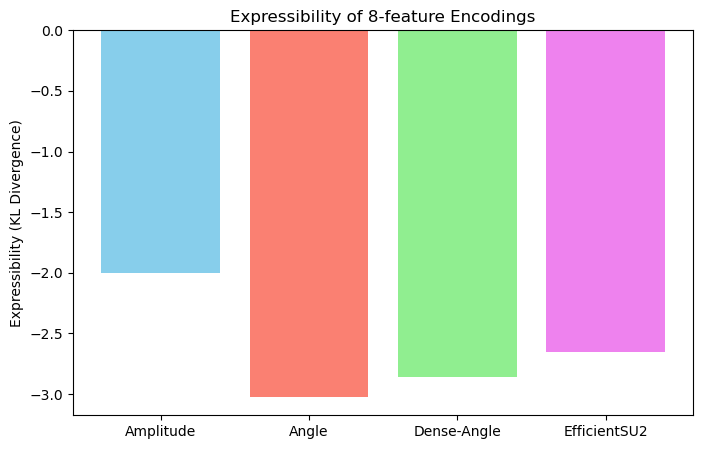

In [41]:
# --- Example usage with your dataset ---
from tqdm import tqdm  # progress bar
X = first_n_scaled_testing_data

encoding_fns = {
    "Amplitude": amplitude_encoding,
    "Angle": angle_encoding,
    "Dense-Angle": dense_angle_encoding,
    "EfficientSU2": efficient_su2_encoding
}

expressibilities = {}
for name, fn in tqdm(encoding_fns.items(), desc="Computing expressibility", unit="encoding"):
    expressibilities[name] = compute_expressibility_dataset(fn, X)
    tqdm.write(f"{name} expressibility ≈ {expressibilities[name]:.3f}")

# === Plot ===
plt.figure(figsize=(8,5))
plt.bar(expressibilities.keys(), expressibilities.values(),
        color=['skyblue','salmon','lightgreen','violet'])
plt.ylabel("Expressibility (KL Divergence)")
plt.title("Expressibility of 8-feature Encodings")
plt.show()

In [42]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from qiskit.quantum_info import Statevector
from tqdm import tqdm

def visualize_tsne_for_encoding(encoding_fn, X, y, num_samples=200, seed=42):
    """
    Visualize quantum encoded states in 2D using t-SNE.
    Works with pandas or NumPy inputs.
    """
    # Ensure numpy arrays
    X = np.array(X)
    y = np.array(y)
    
    # Sample indices
    num_samples = min(num_samples, len(X))
    idxs = np.random.choice(len(X), size=num_samples, replace=False)
    
    # Encode states
    states = []
    for i in tqdm(idxs, desc="Encoding states"):
        qc = encoding_fn(X[i])
        sv = Statevector.from_instruction(qc)
        states.append(sv.data)
    
    states = np.array(states)  # shape: (num_samples, dim)
    
    # Flatten real+imag for t-SNE
    features_real = np.hstack([states.real, states.imag])
    
    # t-SNE
    tsne = TSNE(n_components=2, random_state=seed, perplexity=30)
    coords = tsne.fit_transform(features_real)  # shape: (num_samples, 2)
    
    # Plot
    plt.figure(figsize=(7,5))
    normal_mask = (y[idxs] == 0)
    anomalous_mask = (y[idxs] == 1)
    
    if np.sum(normal_mask) > 0:
        plt.scatter(coords[normal_mask, 0], coords[normal_mask, 1], 
                    alpha=0.6, c='blue', label='Normal')
    if np.sum(anomalous_mask) > 0:
        plt.scatter(coords[anomalous_mask, 0], coords[anomalous_mask, 1], 
                    alpha=0.6, c='red', label='Anomalous')
    
    plt.title(f"t-SNE of Encoded States — {encoding_fn.__name__}")
    plt.xlabel("t-SNE 1")
    plt.ylabel("t-SNE 2")
    plt.legend()
    plt.show()



--- Amplitude Encoding ---


Encoding states: 100%|██████████████████████| 300/300 [00:00<00:00, 1071.04it/s]


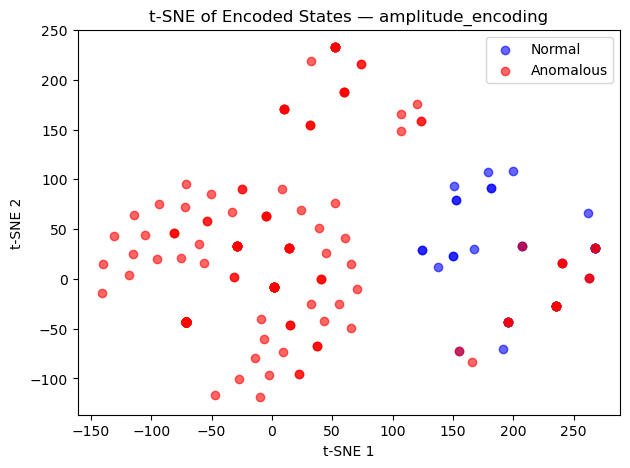


--- Angle Encoding ---


Encoding states: 100%|██████████████████████| 300/300 [00:00<00:00, 1177.06it/s]


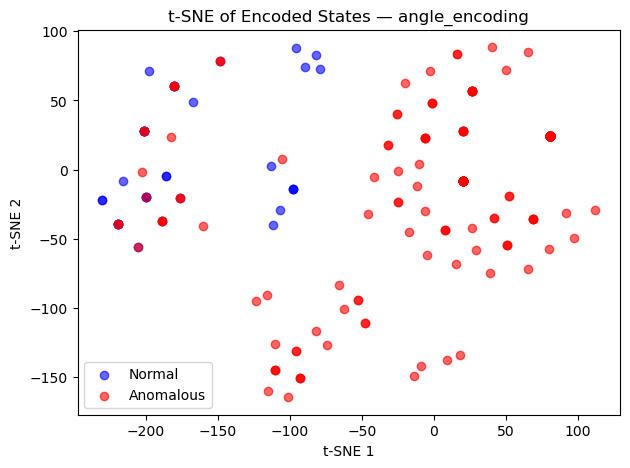


--- Dense-Angle Encoding ---


Encoding states: 100%|██████████████████████| 300/300 [00:00<00:00, 1210.46it/s]


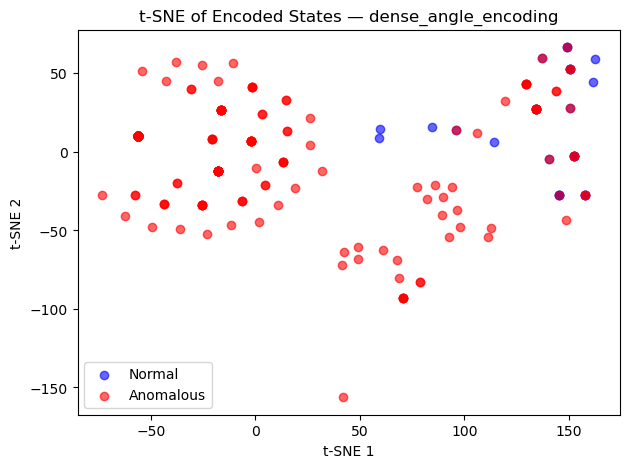


--- EfficientSU2 Encoding ---


Encoding states: 100%|███████████████████████| 300/300 [00:01<00:00, 202.51it/s]


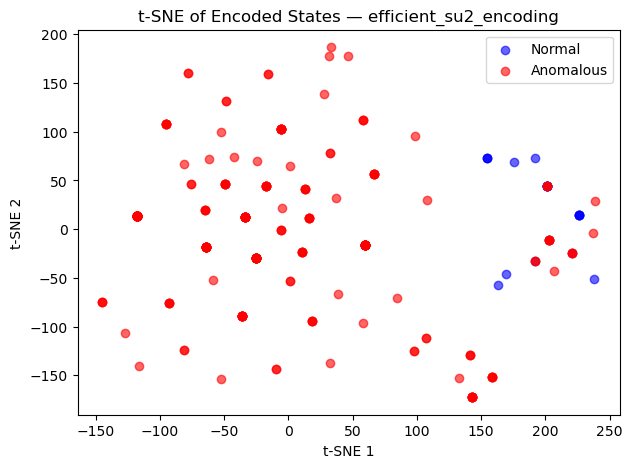

In [48]:
X = first_n_scaled_testing_data   # already a NumPy array
y = testing_labels        # already a NumPy array (or convert with np.array(testing_labels) if it’s a list/Series)


encoding_fns = {
    "Amplitude": amplitude_encoding,
    "Angle": angle_encoding,
    "Dense-Angle": dense_angle_encoding,
    "EfficientSU2": efficient_su2_encoding
}

for name, fn in encoding_fns.items():
    print(f"\n--- {name} Encoding ---")
    visualize_tsne_for_encoding(fn, X, y, num_samples=300)


--- Amplitude Encoding ---


Encoding states: 100%|██████████████████████| 300/300 [00:00<00:00, 1260.41it/s]


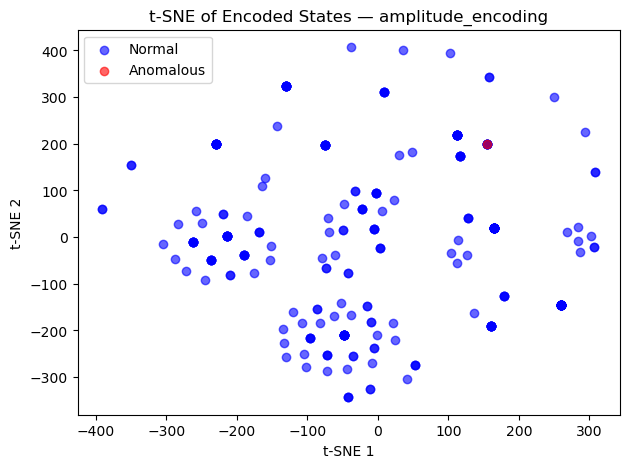


--- Angle Encoding ---


Encoding states: 100%|██████████████████████| 300/300 [00:00<00:00, 1158.44it/s]


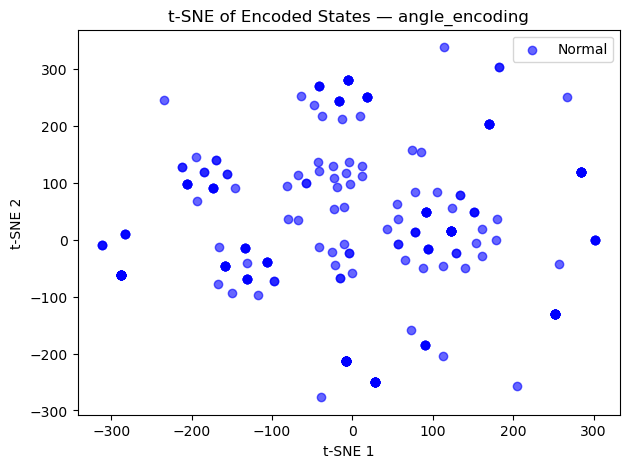


--- Dense-Angle Encoding ---


Encoding states: 100%|██████████████████████| 300/300 [00:00<00:00, 1090.44it/s]


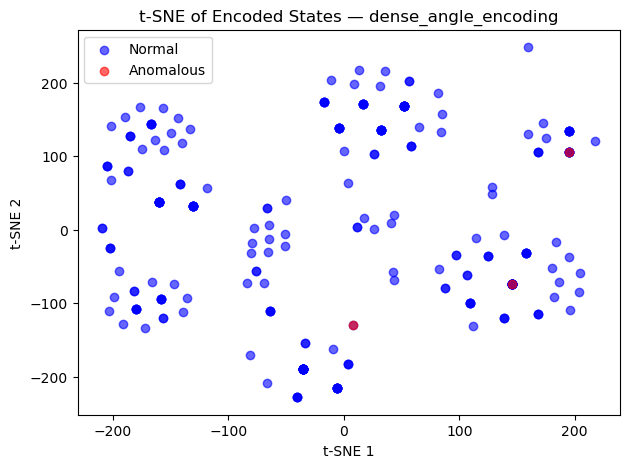


--- EfficientSU2 Encoding ---


Encoding states: 100%|███████████████████████| 300/300 [00:01<00:00, 174.20it/s]


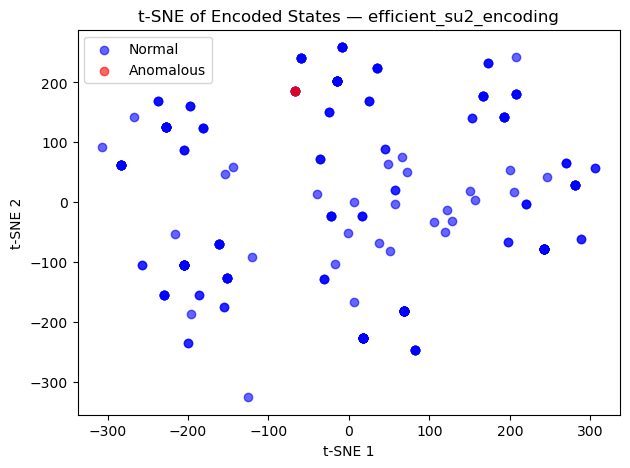

In [44]:
X = first_n_scaled_normal_training_data   # already a NumPy array
y = training_labels        # already a NumPy array (or convert with np.array(testing_labels) if it’s a list/Series)


encoding_fns = {
    "Amplitude": amplitude_encoding,
    "Angle": angle_encoding,
    "Dense-Angle": dense_angle_encoding,
    "EfficientSU2": efficient_su2_encoding
}

for name, fn in encoding_fns.items():
    print(f"\n--- {name} Encoding ---")
    visualize_tsne_for_encoding(fn, X, y, num_samples=300)

In [45]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE

def tsne_plot_raw(X, y, title="t-SNE of Raw Data", num_samples=300, seed=42):
    """
    t-SNE visualization of raw data.
    X: ndarray (N_samples, N_features)
    y: labels (0 normal, 1 anomalous)
    """
    X = np.array(X)
    y = np.array(y)
    
    # Sample a subset for faster computation
    num_samples = min(num_samples, len(X))
    idxs = np.random.choice(len(X), size=num_samples, replace=False)
    X_sample = X[idxs]
    y_sample = y[idxs]
    
    tsne = TSNE(n_components=2, random_state=seed, perplexity=30)
    coords = tsne.fit_transform(X_sample)
    
    plt.figure(figsize=(7,5))
    plt.scatter(coords[y_sample==0, 0], coords[y_sample==0, 1], 
                c='blue', alpha=0.6, label='Normal')
    plt.scatter(coords[y_sample==1, 0], coords[y_sample==1, 1], 
                c='red', alpha=0.6, label='Anomalous')
    plt.title(title)
    plt.xlabel("t-SNE 1")
    plt.ylabel("t-SNE 2")
    plt.legend()
    plt.show()

def feature_variances(X):
    """Compute variance per feature."""
    X = np.array(X)
    return np.var(X, axis=0)

def tsne_and_variance_random_features(X, y, N, seed=42, num_samples=300):
    """
    Select N random features, plot t-SNE and feature variances.
    
    X: ndarray (num_samples, num_features)
    y: labels (0 normal, 1 anomalous)
    N: number of features to randomly select
    """
    np.random.seed(seed)
    feature_indices = np.random.choice(X.shape[1], size=N, replace=False)
    print(f"Random feature indices: {feature_indices}")
    
    X_random = X[:, feature_indices]
    
    # t-SNE plot
    tsne_plot_raw(X_random, y, title=f"t-SNE: Random {N} Features", num_samples=num_samples)
    
    # Feature variances
    var_random = feature_variances(X_random)
    plt.figure(figsize=(8,4))
    plt.bar(np.arange(N), var_random, color='orange', alpha=0.8)
    plt.xlabel("Feature Index (Random Subset)")
    plt.ylabel("Variance")
    plt.title(f"Variances of Random {N} Features")
    plt.show()
    
    return feature_indices, var_random


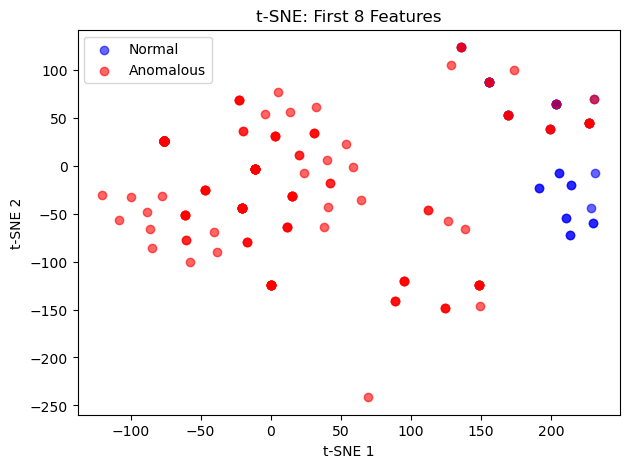

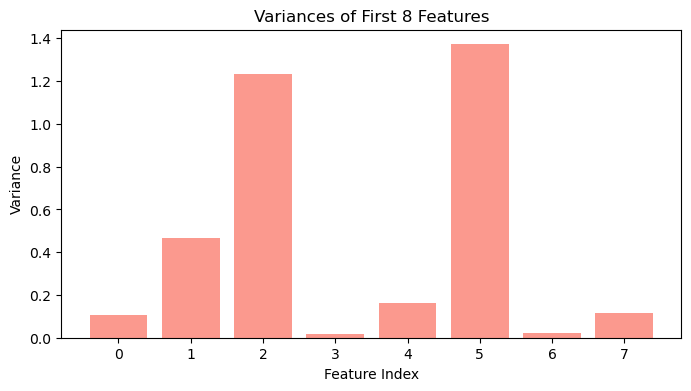

In [52]:
N = 8
feature_indices = np.arange(N)       # first N features
X_firstN = scaled_testing_data[:, feature_indices]

# t-SNE
tsne_plot_raw(X_firstN, y, title=f"t-SNE: First {N} Features", num_samples=300)

# Variance
var_firstN = feature_variances(X_firstN)
plt.figure(figsize=(8,4))
plt.bar(np.arange(N), var_firstN, color='salmon', alpha=0.8)
plt.xlabel("Feature Index")
plt.ylabel("Variance")
plt.title(f"Variances of First {N} Features")
plt.show()


Random feature indices: [18 23  7 14 10 13  8 21]


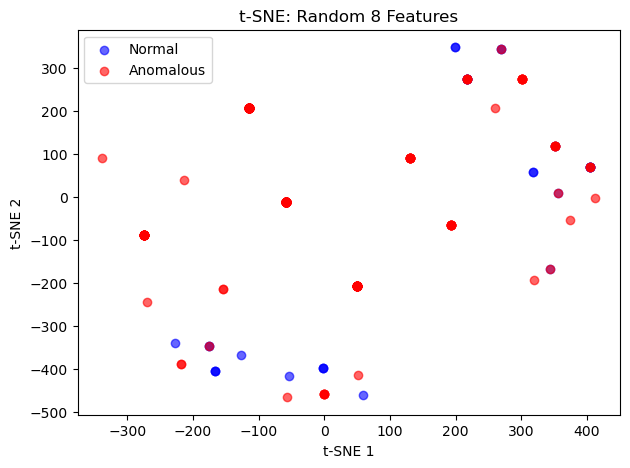

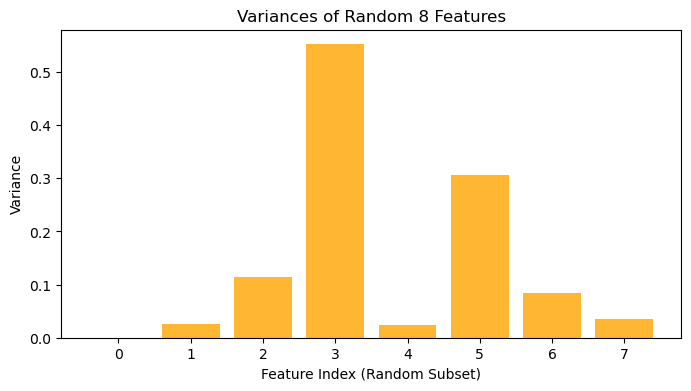

In [76]:
N = 8
random_indices, random_vars = tsne_and_variance_random_features(scaled_testing_data, y, N, seed=12)

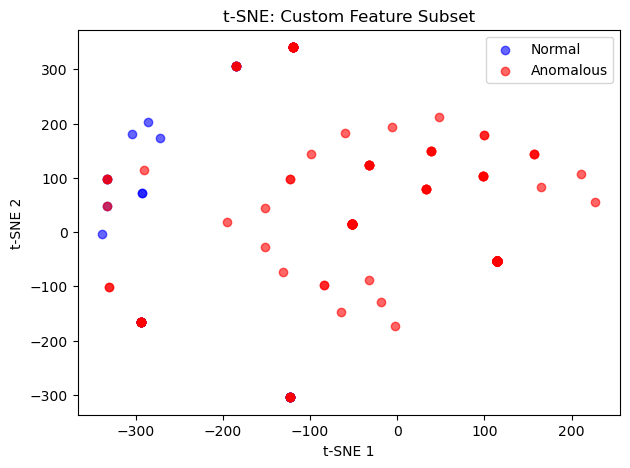

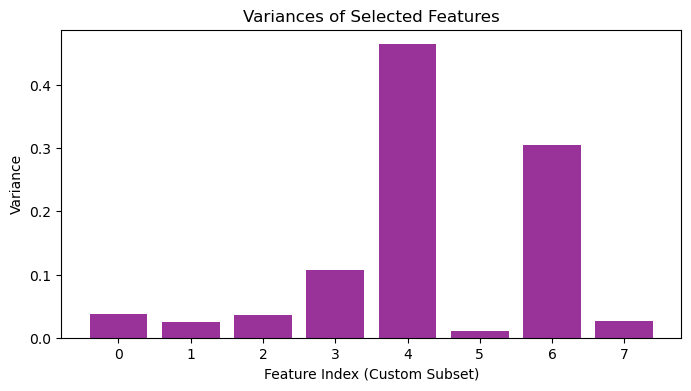

In [72]:
# Define the specific features you want
feature_indices = [20, 10, 15, 0, 1, 11, 13, 9]

# Slice your dataset
X_selected = scaled_testing_data[:, feature_indices]

# t-SNE
tsne_plot_raw(X_selected, y, title=f"t-SNE: Custom Feature Subset")

# Feature variances
var_selected = feature_variances(X_selected)
plt.figure(figsize=(8,4))
plt.bar(np.arange(len(feature_indices)), var_selected, color='purple', alpha=0.8)
plt.xlabel("Feature Index (Custom Subset)")
plt.ylabel("Variance")
plt.title("Variances of Selected Features")
plt.show()


Balanced feature indices: [22 18 19 17 23  9  2  5]


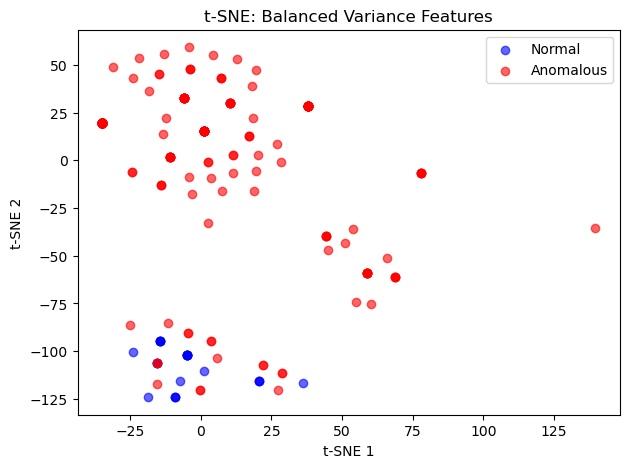

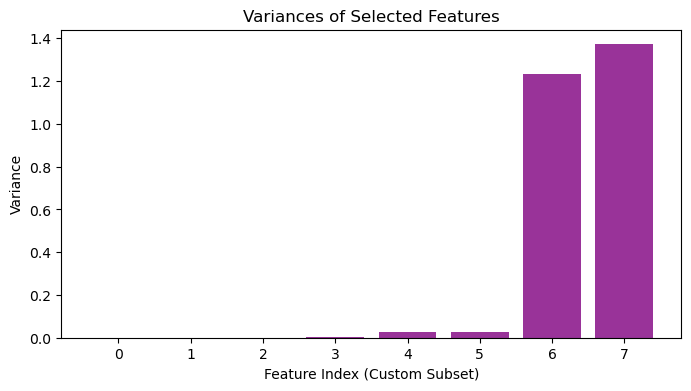

In [106]:
import numpy as np

X = np.array(scaled_testing_data)  # your dataset
var = np.var(X, axis=0)            # variance per feature
sorted_indices = np.argsort(var)  # low → high
N_total = 8

# Compute number from each category
N_each_low  = 4        
N_each_mid  = 2        
N_each_high = 2

# Pick indices
low_idx  = sorted_indices[:N_each_low]
mid_idx  = sorted_indices[len(sorted_indices)//3 : len(sorted_indices)//3 + N_each_mid]
high_idx = sorted_indices[-N_each_high:]

balanced_indices = np.concatenate([low_idx, mid_idx, high_idx])
print("Balanced feature indices:", balanced_indices)
X_balanced = X[:, balanced_indices]

tsne_plot_raw(X_balanced, y, title="t-SNE: Balanced Variance Features")

var_selected = feature_variances(X_balanced)
plt.figure(figsize=(8,4))
plt.bar(np.arange(len(feature_indices)), var_selected, color='purple', alpha=0.8)
plt.xlabel("Feature Index (Custom Subset)")
plt.ylabel("Variance")
plt.title("Variances of Selected Features")
plt.show()
